# Bu kod ne yapıyor?

SemEval 2027 CLaS görevinde modelin ağırlıkları değişmez. Soru bir dilde gelir, cevap başka bir dilde yazılır. Bunu prompta "Türkçe cevap ver" yazarak yapmıyoruz. Model cümleyi üretirken, içindeki sayı vektörüne küçük bir dil vektörü ekliyoruz.

Bu defter üç şeyi yan yana koyar: dosyaların işi, skorun formülü, ve CLaS-Bench makalesindeki gerçek sayılar. İki boyutlu ok çizimi bir oyuncaktır; gerçek Llama vektörü 4096 sayıdır. Okun yönü aynı çıkarma işlemidir.


## Dosyalar, sırayla

Bir soru-cevap şöyle akar.

1. `third_party/CLaS-SemEval-2027` organizatörlerin kodu. Dil listesi, veri indirme ve puanlama orada. Bu deponun içinde durur, commit `2702627`. Klonlayan kişinin ikinci bir depo indirmesine gerek yoktur.
2. `collect.py` FLORES cümlelerini modele okutur. Her dil için, seçilen katmanda, cümlenin son gerçek token'ındaki gizli durumu ortalar.
3. `vectors.py` iki ortalamayı çıkarır ve uzunluğu 1 olacak şekilde böler. Buna DiffMean denir.
4. `hooks.py` üretim sırasında o katmanda `h = h + alpha * v` yapar. Ağırlık dosyasına yazmaz.
5. `generate.py` soruyu sohbet şablonuyla verir, açgözlü üretir (`do_sample=False`) ve organizatörlerin okuduğu JSON'u kurar.
6. `run_slice.py` bunu küçük bir dil listesinde çalıştıran komuttur. `--dry-run` model indirmez, sadece planı basar.
7. `pairs.py` ilk deneme çiftlerini ve T1/T2/T3 etiketini tutar.
8. `evaluate.py` bizim paketimizde yok. Resmi depodaki scorer dil tespiti ve soruyla ilgiyi ölçer.

İlk deneme çiftleri: İngilizce→Almanca, İngilizce→Türkçe, Arapça→İngilizce, İngilizce→Svahili, İngilizce→Maltaca, Rusça→Ukraynaca. Svahili ve Maltaca makalede zayıf kalan diller. Türkçe T2 hedefi.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "clas_steer").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from clas_steer.generate import build_record
from clas_steer.pairs import DEFAULT_PAIRS, infer_track, method_name
from clas_steer.official import import_official
from clas_steer.vectors import diffmean

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120


## Görevde kaç çift var?

T1: 10 yüksek kaynaklı dilin birbirine çevrilmesi, aynı dil hariç, 90 çift.
T2: o 10 kaynaktan 10 daha düşük kaynaklı hedefe, 100 çift. Türkçe burada.
T3: 20 dilin üç hedefe (`ja`, `ru`, `de`) ayrı ayrı çevrilmesi, hedef başına 19 kaynak.
Bonus: yüksek kaynaklı 10 dilde hem reddet hem hedef dilde yaz, aynı dil dahil, 100 çift.


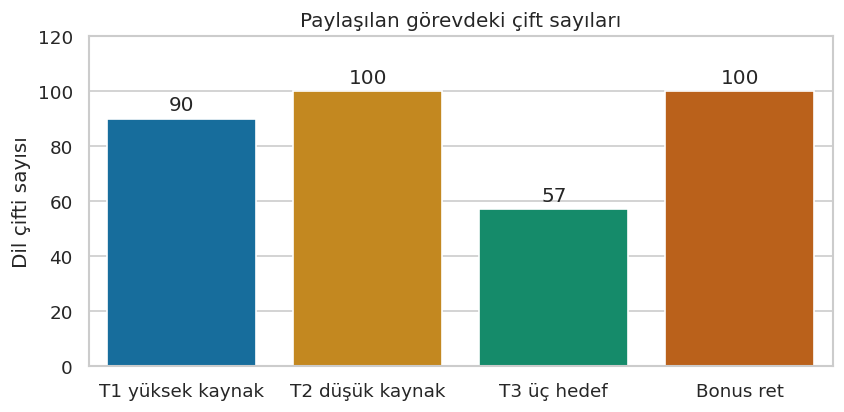

In [2]:
tracks = pd.DataFrame(
    {
        "parkur": ["T1 yüksek kaynak", "T2 düşük kaynak", "T3 üç hedef", "Bonus ret"],
        "cift": [90, 100, 19 * 3, 100],
    }
)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
sns.barplot(data=tracks, x="parkur", y="cift", hue="parkur", legend=False, ax=ax, palette="colorblind")
ax.set_xlabel("")
ax.set_ylabel("Dil çifti sayısı")
ax.set_title("Paylaşılan görevdeki çift sayıları")
for bar, value in zip(ax.patches, tracks["cift"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, str(value), ha="center", va="bottom")
ax.set_ylim(0, 120)
fig.tight_layout()


## Bizim ilk dilim

90 ve 100 çiftin hepsini bir anda koşturmuyoruz. Altı çift, kodun doğru bağlandığını görmek için. Etiketler resmi dil listesinden geliyor: iki yüksek kaynaklı dil T1, yüksekten düşüğe T2.


In [3]:
languages, _ = import_official()
slice_rows = []
for source, target in DEFAULT_PAIRS:
    track = infer_track(source, target, languages)
    slice_rows.append({"kaynak": source, "hedef": target, "parkur": track.upper()})
slice_df = pd.DataFrame(slice_rows)
print(method_name("pair", [28], 1.0))
slice_df


diffmean:pair:L28:a1


,kaynak,hedef,parkur
0,en,de,T1
1,en,tr,T2
2,ar,en,T1
3,en,sw,T2
4,en,mt,T2
5,ru,uk,T2


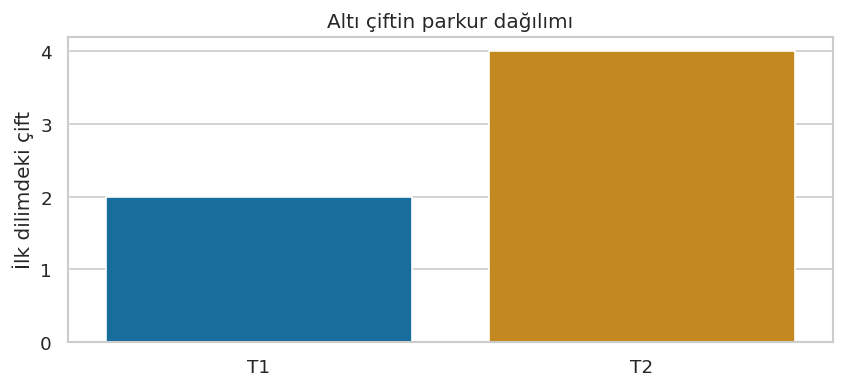

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
sns.countplot(data=slice_df, x="parkur", hue="parkur", legend=False, ax=ax, palette="colorblind")
ax.set_xlabel("")
ax.set_ylabel("İlk dilimdeki çift")
ax.set_title("Altı çiftin parkur dağılımı")
fig.tight_layout()


## DiffMean: dil yönü nasıl bulunuyor?

Aynı katmanda iki ortalama var. Biri hedef dil cümlelerinin gizli durumu, öteki kaynak dil. Çıkar, sonra uzunluğa böl:

`v = (ortalama_hedef - ortalama_kaynak) / uzunluk`

Aşağıdaki noktalar uydurma 2 boyut. `diffmean` fonksiyonu projedeki fonksiyon. Gerçek koleksiyon 4096 boyutta, FLORES cümlelerinin son token'ında yapılır.


birim vektör [0.8240419030189514, 0.566528856754303] uzunluk 1.0


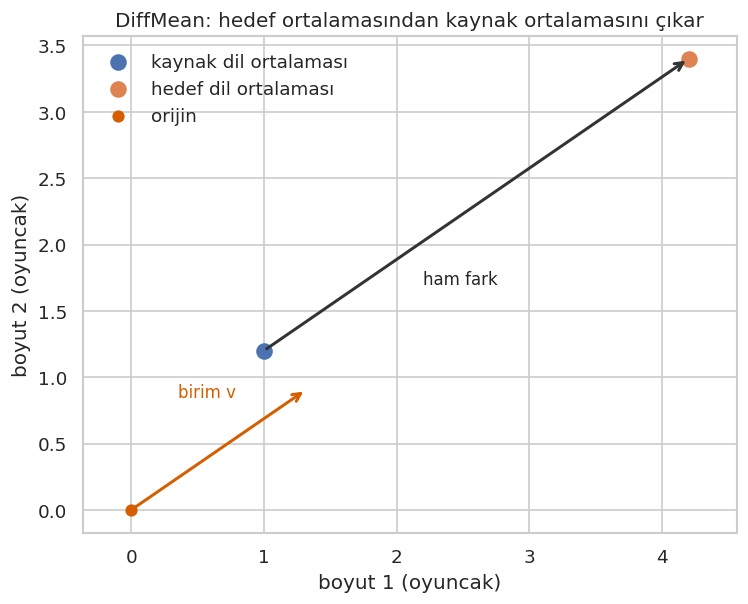

In [5]:
source_mean = torch.tensor([1.0, 1.2])
target_mean = torch.tensor([4.2, 3.4])
direction = diffmean(target_mean, source_mean)
print("birim vektör", direction.tolist(), "uzunluk", float(direction.norm()))

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.scatter([source_mean[0]], [source_mean[1]], s=80, label="kaynak dil ortalaması", zorder=3)
ax.scatter([target_mean[0]], [target_mean[1]], s=80, label="hedef dil ortalaması", zorder=3)
ax.annotate(
    "",
    xy=target_mean.tolist(),
    xytext=source_mean.tolist(),
    arrowprops=dict(arrowstyle="->", lw=1.8, color="#333333"),
)
ax.annotate(
    "",
    xy=(direction * 1.6).tolist(),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle="->", lw=1.8, color="#d55e00"),
)
ax.scatter([0], [0], s=40, color="#d55e00", label="orijin", zorder=3)
ax.text(2.2, 1.7, "ham fark", fontsize=10)
ax.text(0.35, 0.85, "birim v", color="#d55e00", fontsize=10)
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("boyut 1 (oyuncak)")
ax.set_ylabel("boyut 2 (oyuncak)")
ax.set_title("DiffMean: hedef ortalamasından kaynak ortalamasını çıkar")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()


## Üretim anında ne ekleniyor?

`alpha` bu birim vektörün katsayısı. Gizli durum `h` aynı yönde kayar. Katsayı büyüdükçe dil daha güçlü çekilir; cevap da sorudan uzaklaşabilir. Aşağıdaki `h` yine 2 boyutlu bir örnek.


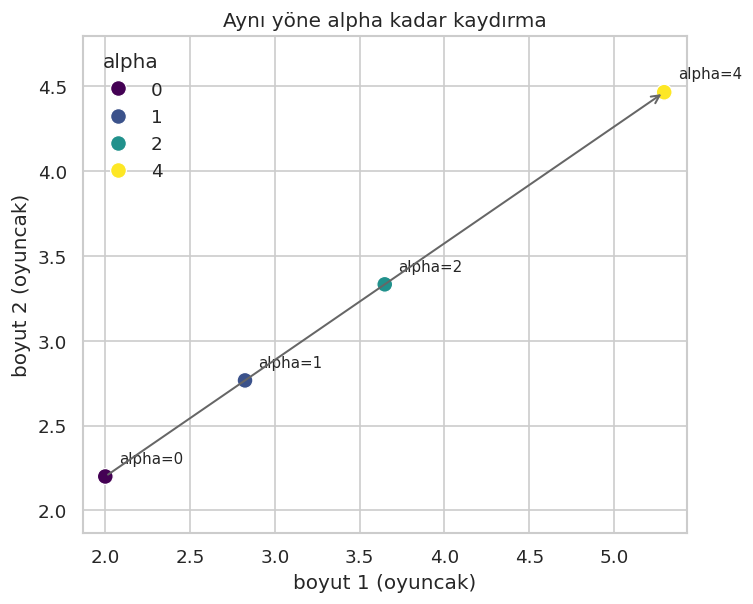

In [6]:
hidden = torch.tensor([2.0, 2.2])
rows = []
for alpha in (0, 1, 2, 4):
    shifted = hidden + alpha * direction
    rows.append({"alpha": alpha, "x": float(shifted[0]), "y": float(shifted[1])})
shift_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.scatterplot(data=shift_df, x="x", y="y", hue="alpha", palette="viridis", s=90, ax=ax)
for _, row in shift_df.iterrows():
    ax.text(row["x"] + 0.08, row["y"] + 0.08, f"alpha={int(row['alpha'])}", fontsize=9)
ax.annotate(
    "",
    xy=shift_df.loc[shift_df["alpha"] == 4, ["x", "y"]].values[0],
    xytext=shift_df.loc[shift_df["alpha"] == 0, ["x", "y"]].values[0],
    arrowprops=dict(arrowstyle="->", lw=1.2, color="#666666"),
)
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("boyut 1 (oyuncak)")
ax.set_ylabel("boyut 2 (oyuncak)")
ax.set_title("Aynı yöne alpha kadar kaydırma")
ax.legend(title="alpha", frameon=False)
fig.tight_layout()


## Puan neden harmonik ortalama?

LFS: cevapların hedef dilde sayılma oranı, 0 ile 1 arası.
OR: cevabın soruyla ilgili olma puanı, 0, 1 veya 2; sonra 2'ye bölününce yine 0 ile 1.
LSS = 2 · LFS · OR / (LFS + OR).

Biri 0 ise LSS de 0'dır. Dil doğru ama saçma metin, ya da soruya cevap ama yanlış dil, ikisi de düşük skor alır. Izgara formülün kendisidir, bir deney sonucu değildir.


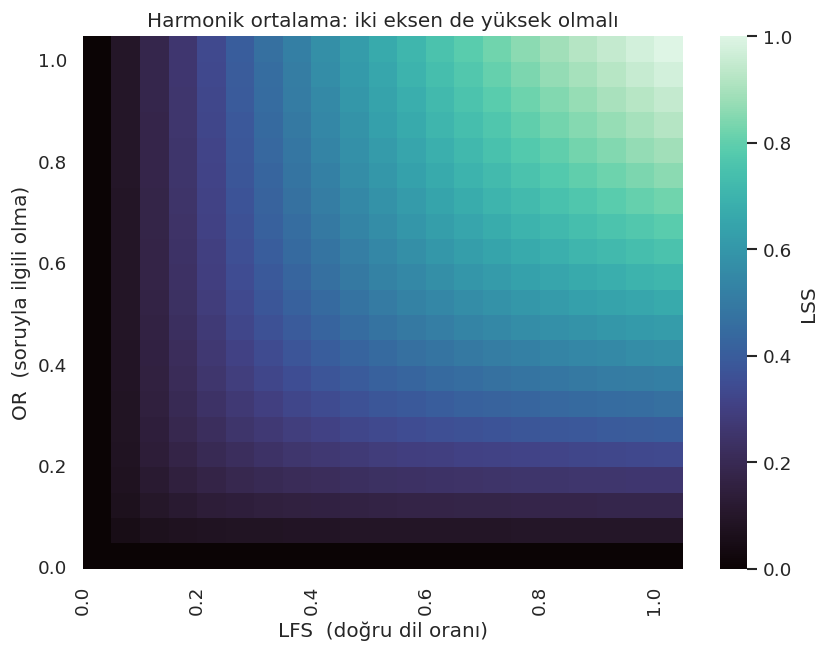

In [7]:
import numpy as np

grid = np.linspace(0, 1, 21)
lfs, relevance = np.meshgrid(grid, grid)
total = lfs + relevance
lss = np.zeros_like(total)
mask = total > 0
lss[mask] = 2 * lfs[mask] * relevance[mask] / total[mask]
heat = pd.DataFrame(lss, index=np.round(grid, 2), columns=np.round(grid, 2))

fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(heat, ax=ax, cmap="mako", vmin=0, vmax=1, cbar_kws={"label": "LSS"})
step = 4
ax.set_xticks(range(0, len(grid), step))
ax.set_xticklabels([f"{value:.1f}" for value in grid[::step]])
ax.set_yticks(range(0, len(grid), step))
ax.set_yticklabels([f"{value:.1f}" for value in grid[::step]])
ax.set_xlabel("LFS  (doğru dil oranı)")
ax.set_ylabel("OR  (soruyla ilgili olma)")
ax.set_title("Harmonik ortalama: iki eksen de yüksek olmalı")
ax.invert_yaxis()
fig.tight_layout()


## Makaledeki gerçek DiffMean skorları

Sayılar CLaS-Bench Tablo 2'den. Model Llama-3.1-8B-Instruct, sütun DiffMean, 32 dil üzerindeki dil başına LSS. Burada sadece paylaşılan görevdeki 20 dil var. Maltaca 15.6, Svahili 49.8. Türkçe 84.5. Bunlar bizim henüz üretmediğimiz koşular; makalenin bildirdiği sonuçlar.


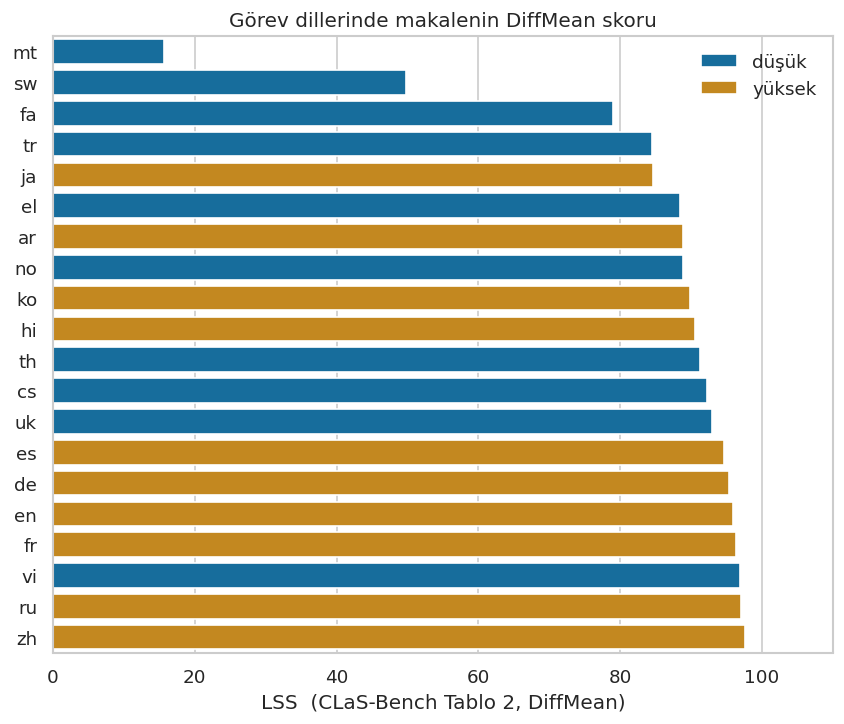

In [8]:
paper = pd.DataFrame(
    [
        ("ar", "yüksek", 88.8), ("de", "yüksek", 95.4), ("en", "yüksek", 95.9),
        ("es", "yüksek", 94.7), ("fr", "yüksek", 96.4), ("ja", "yüksek", 84.6),
        ("zh", "yüksek", 97.6), ("ru", "yüksek", 97.0), ("hi", "yüksek", 90.5),
        ("ko", "yüksek", 89.8), ("cs", "düşük", 92.3), ("el", "düşük", 88.4),
        ("fa", "düşük", 79.0), ("vi", "düşük", 96.9), ("uk", "düşük", 92.9),
        ("mt", "düşük", 15.6), ("no", "düşük", 88.8), ("sw", "düşük", 49.8),
        ("th", "düşük", 91.2), ("tr", "düşük", 84.5),
    ],
    columns=["dil", "grup", "lss"],
).sort_values("lss")

fig, ax = plt.subplots(figsize=(7.2, 6.2))
sns.barplot(data=paper, y="dil", x="lss", hue="grup", dodge=False, ax=ax, palette="colorblind")
ax.set_xlabel("LSS  (CLaS-Bench Tablo 2, DiffMean)")
ax.set_ylabel("")
ax.set_xlim(0, 110)
ax.set_title("Görev dillerinde makalenin DiffMean skoru")
ax.legend(title="", frameon=False, loc="upper right")
fig.tight_layout()


## Aynı tablodaki yöntem ortalamaları

32 dilin ortalaması. DiffMean 84.5 ile önde. Nöron yöntemi (LAPE) 80.1. Prompt tabanları 67 civarı. Probe, SAE, LDA ve PCA geride. Bu yüzden ilk kod DiffMean. Prompt sayılar karşılaştırmadır; resmi sıralama promptla dil değiştirmeyi kabul etmiyor.


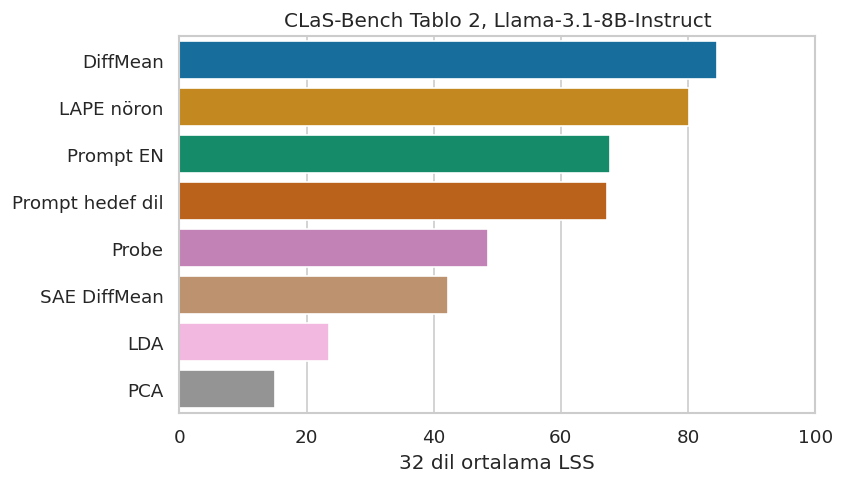

In [9]:
methods = pd.DataFrame(
    {
        "yontem": ["DiffMean", "LAPE nöron", "Prompt EN", "Prompt hedef dil", "Probe", "SAE DiffMean", "LDA", "PCA"],
        "ortalama_lss": [84.5, 80.1, 67.7, 67.3, 48.6, 42.3, 23.6, 15.1],
    }
)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
sns.barplot(data=methods, y="yontem", x="ortalama_lss", hue="yontem", legend=False, ax=ax, palette="colorblind")
ax.set_xlabel("32 dil ortalama LSS")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("CLaS-Bench Tablo 2, Llama-3.1-8B-Instruct")
fig.tight_layout()


## JSON neye benziyor?

`en` sorusu `tr` cevabına giderken dosya `en_to_tr.json` olur. `input` ve `original_prompt` ham sorudur. "Türkçe cevap ver" eklenmez. `output` modelin ürettiği metindir. Aşağıdaki çıktı uydurma bir cümledir; sadece alanların şeklini gösterir. Scorer `output` ile dili, `original_prompt` ile soruyu okur.


In [10]:
record = build_record(
    source="en",
    target="tr",
    model_name="meta-llama/Llama-3.1-8B-Instruct",
    method=method_name("pair", [28], 1.0),
    track="t2",
    questions=["How are you?"],
    outputs=["İyiyim, teşekkürler."],
)
for key in ("source_language", "target_language", "method", "track"):
    print(f"{key}: {record[key]}")
print("results[0]:")
for key, value in record["results"][0].items():
    print(f"  {key}: {value}")


source_language: en
target_language: tr
method: diffmean:pair:L28:a1
track: t2
results[0]:
  question_idx: 0
  input: How are you?
  output: İyiyim, teşekkürler.
  original_prompt: How are you?


## Tek çiftin çalışma sırası

`python src/clas_steer/run_slice.py --layers 28 --alpha 1` şunu yapar.

1. `data/train/en.txt` ve `data/train/tr.txt` içinden en fazla 512 FLORES cümlesi okunur. `--num-sentences 0` dosyanın tamamını kullanır.
2. Model cümleleri görür. 28. katmanda (sayım 0'dan başlar; Llama-3.1-8B'de katmanlar 0–31) son gerçek token'ın gizli durumu ortalanır. Ortalama `vectors/.../means/` altına yazılır.
3. `v = diffmean(ortalama_tr, ortalama_en)`.
4. `data/validation/en.txt` soruları sohbet şablonuyla verilir. 28. katmanda her token'a `alpha * v` eklenir.
5. Cevaplar `generations/Llama-3.1-8B-Instruct/t2/diffmean/en_to_tr.json` dosyasına yazılır.
6. Puan için resmi deponun içinden `python evaluate.py --gen-dir ...` çalışır. O adım vLLM ve fastText ister; bu defter onu çalıştırmaz.

`--contrast others` kaynak dili çıkarmaz. Hedefin ortalamasından, o koşudaki diğer dillerin ortalamasını çıkarır. Aynı Türkçe vektörü her kaynak için tekrar kullanılır.

`--dry-run` 1–6 adımlarının hiçbirini yapmaz. Çiftleri, parkur etiketini ve dosyaların diskte olup olmadığını basar.
